# Evaluación — Red Neuronal Multicapa (MLP) para clasificación
## Dataset: *Bank Marketing* (UCI Machine Learning Repository)

### Contexto del problema

Un banco portugués realizó **campañas de marketing telefónico** para ofrecer a sus clientes un **depósito a plazo**. Por cada cliente contactado se registraron sus datos personales, su situación financiera y el historial de contactos de la campaña.

**Objetivo:** construir un modelo que prediga si un cliente **contratará el depósito a plazo** (`y = "yes"`) o **no** (`y = "no"`).

| | |
|---|---|
| **Tipo de problema** | Clasificación **binaria** |
| **Registros** | 45.211 clientes |
| **Variables de entrada** | 16 (7 numéricas y 9 categóricas) |
| **Variable objetivo** | `y` ("yes" / "no") |
| **Fuente** | [UCI Machine Learning Repository — Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing) |
| **Licencia** | CC BY 4.0 |
| **Cita** | Moro, S., Cortez, P. & Rita, P. (2014). *A data-driven approach to predict the success of bank telemarketing.* Decision Support Systems, 62, 22–31. |

## ¿Qué deben demostrar?

1. Cargar y **preprocesar** correctamente los datos.
2. **Diseñar e implementar** una arquitectura MLP (TensorFlow/Keras o PyTorch).
3. Configurar **parámetros de entrenamiento**: épocas, tasa de aprendizaje y tamaño de batch.
4. **Comparar** distintas funciones de **activación** y funciones de **pérdida**.
5. Aplicar técnicas de **optimización** y **regularización**.
6. **Evaluar** el desempeño con **Accuracy, Precision, Recall y F1-Score**.
7. **Analizar** los resultados y **justificar** las mejoras realizadas al modelo.

> Este notebook **solo carga y describe los datos**. Todo el preprocesamiento, el modelo y el análisis son parte de su trabajo.

## 1. Cargar los datos

Ejecuta **una** de las dos opciones.

**Opción A (recomendada): descarga directa desde UCI.** Funciona en Google Colab y en Jupyter local. Solo requiere internet.

In [ ]:
import io
import zipfile
import urllib.request

import pandas as pd
import matplotlib.pyplot as plt

URL_UCI = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

with urllib.request.urlopen(URL_UCI) as resp:
    zip_externo = zipfile.ZipFile(io.BytesIO(resp.read()))
zip_interno = zipfile.ZipFile(io.BytesIO(zip_externo.read("bank.zip")))   # el archivo viene comprimido dos veces
df = pd.read_csv(zip_interno.open("bank-full.csv"), sep=";")

print("Datos cargados:", df.shape[0], "filas x", df.shape[1], "columnas")

**Opción B: desde el archivo `bank_marketing.csv` entregado por el docente.**

- **En Colab:** sube el archivo con el ícono de carpeta (panel izquierdo → *Subir*) y ejecuta la celda.
- **En Jupyter local:** deja el CSV en la misma carpeta que este notebook.
- **Desde un enlace** (Google Drive / GitHub): pega el enlace en `ENLACE`. Si es de Google Drive, el archivo debe estar compartido como *"Cualquier persona con el enlace"*.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
ENLACE = ""   # opcional: pega aquí el enlace entregado por el docente

def enlace_descarga(url):
    # Convierte un enlace "compartir" de Google Drive en un enlace de descarga directa
    if "drive.google.com" in url and "/d/" in url:
        file_id = url.split("/d/")[1].split("/")[0]
        return f"https://drive.google.com/uc?export=download&id={file_id}"
    return url

df = pd.read_csv(enlace_descarga(ENLACE) if ENLACE else "bank_marketing.csv")
print("Datos cargados:", df.shape[0], "filas x", df.shape[1], "columnas")

Datos cargados: 45211 filas x 17 columnas


## 2. Diccionario de variables

**Datos del cliente**

| Variable | Tipo | Descripción |
|---|---|---|
| `age` | numérica | Edad |
| `job` | categórica | Tipo de trabajo (`admin.`, `blue-collar`, `entrepreneur`, `housemaid`, `management`, `retired`, `self-employed`, `services`, `student`, `technician`, `unemployed`, `unknown`) |
| `marital` | categórica | Estado civil (`married`, `single`, `divorced` — "divorced" incluye viudos) |
| `education` | categórica | Nivel educacional (`primary`, `secondary`, `tertiary`, `unknown`) |
| `default` | binaria | ¿Tiene créditos en mora? (`yes` / `no`) |
| `balance` | numérica | Saldo promedio anual, en euros (puede ser negativo) |
| `housing` | binaria | ¿Tiene crédito hipotecario? |
| `loan` | binaria | ¿Tiene crédito de consumo? |

**Último contacto de la campaña actual**

| Variable | Tipo | Descripción |
|---|---|---|
| `contact` | categórica | Medio de contacto (`cellular`, `telephone`, `unknown`) |
| `day` | numérica | Día del mes del último contacto |
| `month` | categórica | Mes del último contacto (`jan` … `dec`) |
| `duration` | numérica | Duración del último contacto, en segundos ⚠️ *(ver nota importante más abajo)* |

**Otros atributos**

| Variable | Tipo | Descripción |
|---|---|---|
| `campaign` | numérica | N° de contactos realizados a este cliente en esta campaña (incluye el último) |
| `pdays` | numérica | Días transcurridos desde el último contacto de una campaña **anterior** (`-1` = nunca fue contactado antes) |
| `previous` | numérica | N° de contactos realizados antes de esta campaña |
| `poutcome` | categórica | Resultado de la campaña anterior (`success`, `failure`, `other`, `unknown`) |

**Variable objetivo**

| Variable | Tipo | Descripción |
|---|---|---|
| `y` | binaria | ¿El cliente contrató el depósito a plazo? (`yes` / `no`) |

## 3. Primera mirada a los datos

In [3]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [5]:
df.describe().round(2)

,age,balance,day,duration,campaign,pdays,previous
count,45211.00,45211.00,45211.00,45211.00,45211.00,45211.00,45211.00
mean,40.94,1362.27,15.81,258.16,2.76,40.20,0.58
std,10.62,3044.77,8.32,257.53,3.10,100.13,2.30
min,18.00,-8019.00,1.00,0.00,1.00,-1.00,0.00
25%,33.00,72.00,8.00,103.00,1.00,-1.00,0.00
50%,39.00,448.00,16.00,180.00,2.00,-1.00,0.00
75%,48.00,1428.00,21.00,319.00,3.00,-1.00,0.00
max,95.00,102127.00,31.00,4918.00,63.00,871.00,275.00


### Distribución de la variable objetivo

,cantidad,porcentaje (%)
y,,
no,39922,88.3
yes,5289,11.7


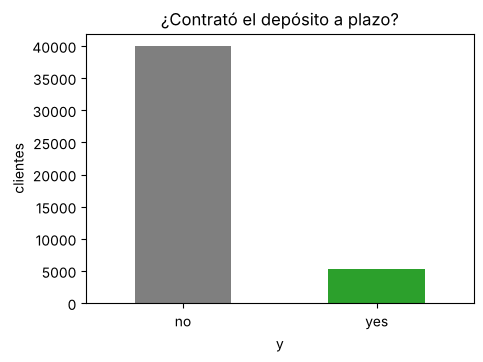

In [6]:
conteo = df["y"].value_counts()
porcentaje = df["y"].value_counts(normalize=True).mul(100).round(1)
display(pd.DataFrame({"cantidad": conteo, "porcentaje (%)": porcentaje}))

conteo.plot(kind="bar", color=["tab:gray", "tab:green"], figsize=(5, 3.5), rot=0,
            title="¿Contrató el depósito a plazo?")
plt.ylabel("clientes")
plt.show()

### Valores "unknown"

El dataset **no tiene celdas vacías**, pero varias columnas categóricas usan el texto `"unknown"` cuando no se conoce el dato.

In [7]:
print("Celdas vacías (NaN):", df.isna().sum().sum())
categoricas = [c for c in df.columns if df[c].dtype == "object" or str(df[c].dtype) == "str"]
unknown = {c: int((df[c] == "unknown").sum()) for c in categoricas}
pd.Series(unknown, name="cantidad de 'unknown'").to_frame().query("`cantidad de 'unknown'` > 0")

Celdas vacías (NaN): 0


,cantidad de 'unknown'
job,288
education,1857
contact,13020
poutcome,36959


## 4. Consideraciones importantes

1. **Clases desbalanceadas.** Solo ~12 % de los clientes contrató el depósito. Un modelo que responda siempre `"no"` obtiene **~88 % de Accuracy** sin haber aprendido nada. Por eso **Precision, Recall y F1-Score** de la clase `"yes"` son fundamentales para evaluar los modelos.
2. **La variable `duration`.** La duración de la llamada solo se conoce **después** de hacerla, y cuando `duration = 0` el resultado siempre es `"no"`. Los autores del dataset recomiendan **no usarla** si el objetivo es un modelo predictivo realista (uno que se use *antes* de llamar al cliente). Decidan si la incluyen o no y **justifiquen** su decisión en el análisis.
3. **Variables categóricas.** La red neuronal necesita números: hay que transformar las variables de texto.
4. **Escalas muy distintas.** Por ejemplo, `balance` va de miles de euros negativos a más de 100.000, mientras que `previous` suele estar entre 0 y 5.
5. **`pdays = -1`** no es un número de días: significa "nunca contactado antes".
6. **Separación de datos.** Todo lo que el preprocesamiento "aprende" (medias, escalas, categorías) debe calcularse **solo con los datos de entrenamiento**.

## 5. Su trabajo comienza aquí ⬇️

Sugerencia de estructura para el notebook de entrega:

1. Análisis exploratorio y preprocesamiento
2. Separación en entrenamiento / validación / prueba
3. Modelo base (MLP) y configuración de entrenamiento
4. Comparación de funciones de activación y de pérdida
5. Optimización y regularización
6. Evaluación final: Accuracy, Precision, Recall, F1-Score y matriz de confusión
7. Análisis de resultados y justificación de las mejoras

# Desarrollo del encargo: MLP para predecir la contratación de un depósito a plazo

## Introducción

**Problema.** Un banco realizó campañas de marketing telefónico para ofrecer un depósito a plazo. Para cada cliente se registraron sus datos personales, su situación financiera y el historial de contactos. Es un problema de **clasificación binaria**: predecir si el cliente contratará el depósito (`y = "yes"`) o no (`y = "no"`).

**Objetivo.** Implementar un perceptrón multicapa (MLP) con TensorFlow/Keras, entrenarlo, ajustar sus hiperparámetros con **experimentos controlados** (cambiando un parámetro a la vez), aplicar técnicas de regularización y evaluarlo con Accuracy, Precision, Recall y F1-Score, justificando cada decisión.

**Criterio para decidir.** Solo ~12 % de los clientes contrata el depósito. Un modelo que siempre responda "no" tendría ~88 % de Accuracy sin aprender nada, por lo que las decisiones se toman mirando el **F1-Score de la clase "yes" en el conjunto de validación**, junto con Precision y Recall. El conjunto de prueba se usa solo al final.

**Reproducibilidad.** Se fija una semilla (`SEMILLA = 42`). En otro computador los decimales pueden variar levemente.

**Guía para la presentación** (en el orden de la pauta):

| Punto de la pauta | Dónde mostrarlo |
|---|---|
| Carga y preprocesamiento de los datos (ejecutando las celdas) | Celdas de carga al inicio y Sección 1 |
| Parámetros de entrenamiento (épocas, tasa de aprendizaje, batch) con experimentos controlados | Sección 3 |
| Evaluar el modelo y ajustarlo según lo observado | Textos de análisis al final de cada sección |
| Funciones de activación, de error y de salida, y su efecto en la convergencia | Secciones 2 y 4 |
| Tabla comparativa de activación y error, y elección de las funciones | Sección 4 |
| MLP en TensorFlow/Keras y ejecución del código | Sección 2 |
| Regularización y Dropout, con gráficos comparativos | Sección 6 |
| Ajuste de hiperparámetros con tabla de pruebas | Secciones 3, 5 y 8 |
| Métricas con cuadro resumen y su cálculo | Secciones 7.2 y 7.3 |
| Interpretar las métricas y mejorar Precision y Recall | Sección 7.4 |
| Comparación de configuraciones y hallazgos clave | Secciones 8 y 9 |

> **Carga de datos:** se usó la **Opción B** (archivo `bank_marketing.csv` entregado por el docente).

In [8]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)
print("TensorFlow", tf.__version__)

I0000 00:00:1791658194.305112     322 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791658194.358890     322 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791658195.716375     322 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 1. Análisis exploratorio y preprocesamiento

### 1.1 Carga de los datos

Los pasos seguidos, con las celdas ubicadas más arriba (Opción B), son:

1. **Importar las librerías:** `pandas` para manejar la tabla de datos y `matplotlib` para los gráficos.
2. **Leer el archivo:** `pd.read_csv("bank_marketing.csv")` carga el archivo entregado por el docente y deja los datos en el DataFrame `df`, con una fila por cliente.
3. **Verificar que la carga fue correcta:** `df.shape` / `df.head()` / `df.info()` / `df.describe()` muestran que se cargaron **45.211 clientes y 17 columnas** (16 variables de entrada y el objetivo `y`), con sus tipos de dato y estadísticas.
4. **Revisar la calidad de los datos:** no hay celdas vacías (0 `NaN`), pero varias columnas de texto usan el valor `"unknown"`; y la variable objetivo está desbalanceada (88,3 % "no" y 11,7 % "yes").

### 1.2 Exploración

Antes de transformar los datos se revisan las escalas de las variables numéricas y si las variables categóricas tienen relación con la contratación del depósito.

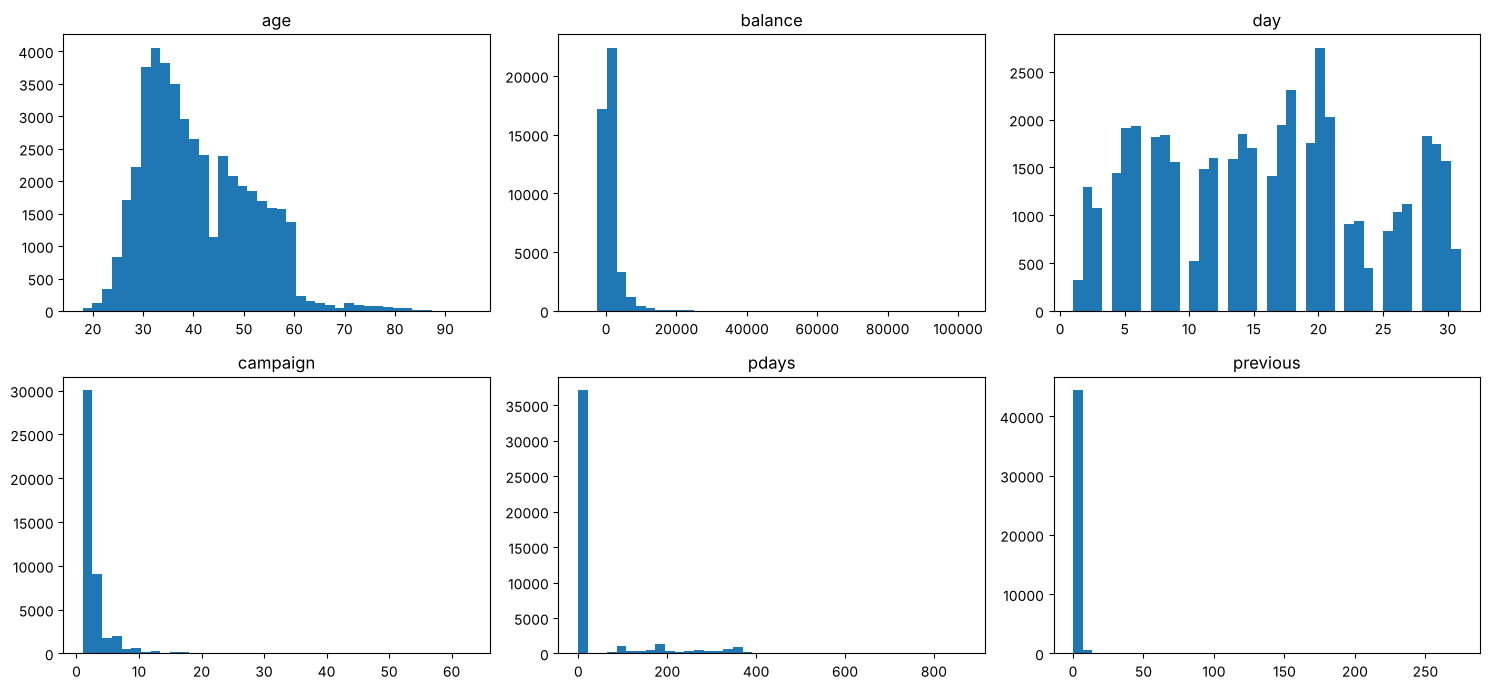

In [9]:
numericas_eda = ["age", "balance", "day", "campaign", "pdays", "previous"]
fig, axs = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axs.ravel(), numericas_eda):
    ax.hist(df[col], bins=40, color="tab:blue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

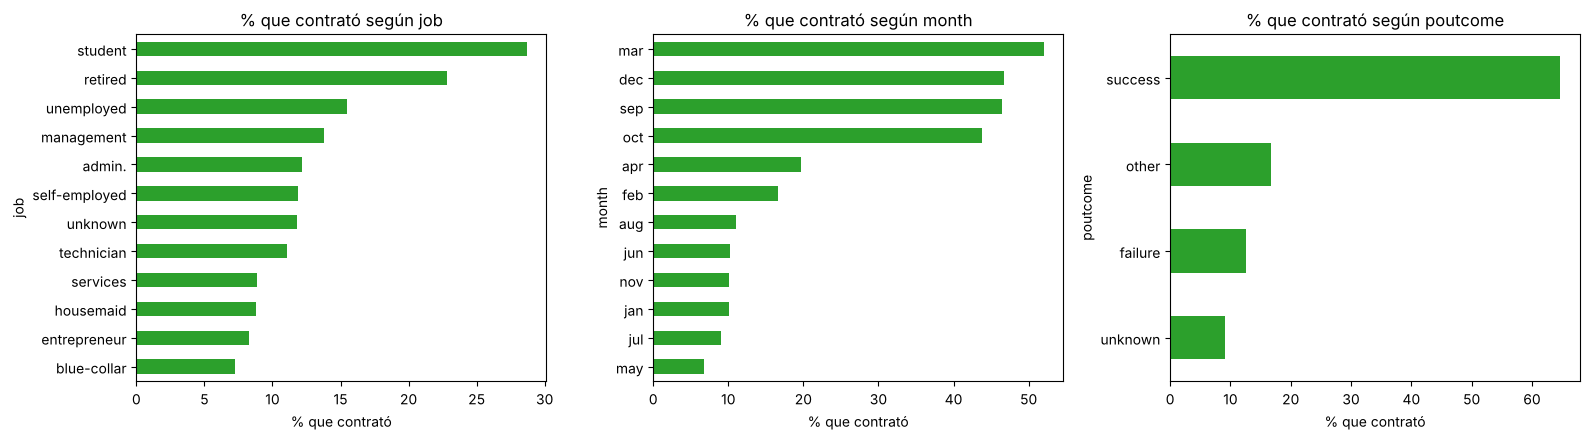

Clientes nunca contactados antes (pdays = -1): 81.7 %
Rango de balance: -8019 a 102127
Duración mediana de la llamada según resultado:
y
no     164.0
yes    426.0
Name: duration, dtype: float64


In [10]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axs, ["job", "month", "poutcome"]):
    tasa = df.groupby(col)["y"].apply(lambda s: (s == "yes").mean() * 100).sort_values()
    tasa.plot(kind="barh", ax=ax, color="tab:green")
    ax.set_title(f"% que contrató según {col}")
    ax.set_xlabel("% que contrató")
plt.tight_layout()
plt.show()

print(f"Clientes nunca contactados antes (pdays = -1): {(df['pdays'] == -1).mean() * 100:.1f} %")
print(f"Rango de balance: {df['balance'].min()} a {df['balance'].max()}")
print(f"Duración mediana de la llamada según resultado:")
print(df.groupby("y")["duration"].median())

**Qué se observa**

- **Escalas muy distintas:** `balance` va de −8.019 a 102.127 euros, mientras que `campaign` y `previous` están casi siempre entre 0 y 5, y hay colas largas hacia la derecha (por ejemplo, un cliente con 275 contactos previos). Por eso hay que **escalar** las variables numéricas.
- **Hay información que la red puede aprender:** la tasa general de contratación es 11,7 %, pero sube a **64,7 %** cuando el resultado de la campaña anterior fue `success`, a **52 %** en marzo (contra 6,7 % en mayo) y a 28,7 % en estudiantes (contra 7,3 % en obreros).
- **`unknown` no es ruido:** el 81,7 % de los clientes no tuvo campaña previa, y esa condición también tiene una tasa distinta al promedio (9,2 %), así que se conserva como una categoría más.
- **`duration` delata el resultado:** la llamada mediana dura 426 s cuando el cliente contrata y 164 s cuando no. Como solo se conoce después de llamar, se excluye del modelo.

### 1.3 Decisiones de preprocesamiento

La red neuronal solo trabaja con números y es sensible a la escala de las entradas. Se hace lo siguiente:

| Decisión | Qué se hace | Justificación |
|---|---|---|
| **Eliminar `duration`** | La variable no entra al modelo | La duración solo se conoce **después** de llamar al cliente y, si vale 0, el resultado siempre es "no". El modelo debe servir para decidir *a quién llamar*, es decir, antes de la llamada. Los autores del dataset también recomiendan no usarla. |
| **`pdays = -1`** | Se crea `contactado_antes` (1 si `pdays ≠ -1`) y `pdays` pasa a 0 para los nunca contactados | `-1` no es una cantidad de días, significa "nunca contactado". Dejarlo haría creer a la red que está "cerca" de haber sido contactado ayer. |
| **Variables yes/no** (`default`, `housing`, `loan`) y objetivo `y` | `yes` → 1 y `no` → 0 | Una neurona de salida con sigmoide entrega valores entre 0 y 1. |
| **Variables de texto** (`job`, `marital`, `education`, `contact`, `month`, `poutcome`) | **One-hot**: una columna 0/1 por categoría | Numerarlas (1, 2, 3...) inventaría un orden que no existe. |
| **Valores `"unknown"`** | Se dejan como una categoría más | Son informativos (por ejemplo, `poutcome = unknown` significa que no hubo campaña previa). |
| **Variables numéricas** | **Estandarización** (media 0 y varianza 1) | Es la buena práctica vista en clase: sin escalar, `balance` (miles de euros) dominaría sobre `previous` (0 a 5) y la optimización demoraría más en converger. |

### 1.4 Separación de los datos

Se separa en **70 % entrenamiento, 15 % validación y 15 % prueba**, de forma **estratificada** para que cada conjunto conserve ~12 % de clientes "yes".

- **Entrenamiento:** donde la red ajusta sus pesos.
- **Validación:** para comparar configuraciones y detectar sobreajuste.
- **Prueba:** datos nunca vistos, solo para la evaluación final.

La media y desviación del escalado y las columnas del one-hot se calculan **solo con entrenamiento** y luego se aplican a validación y prueba.

In [11]:
datos = df.drop(columns=["duration"]).copy()
datos["contactado_antes"] = (datos["pdays"] != -1).astype(int)
datos.loc[datos["pdays"] == -1, "pdays"] = 0
for col in ["default", "housing", "loan"]:
    datos[col] = (datos[col] == "yes").astype(int)
objetivo = (datos.pop("y") == "yes").astype(int)

X_tr, X_tmp, y_train, y_tmp = train_test_split(datos, objetivo, test_size=0.30, stratify=objetivo, random_state=SEMILLA)
X_va, X_te, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEMILLA)

categoricas = ["job", "marital", "education", "contact", "month", "poutcome"]
X_tr = pd.get_dummies(X_tr, columns=categoricas, dtype=int)
columnas = X_tr.columns
X_va = pd.get_dummies(X_va, columns=categoricas, dtype=int).reindex(columns=columnas, fill_value=0)
X_te = pd.get_dummies(X_te, columns=categoricas, dtype=int).reindex(columns=columnas, fill_value=0)

numericas = ["age", "balance", "day", "campaign", "pdays", "previous"]
escalador = StandardScaler().fit(X_tr[numericas])
X_tr[numericas] = escalador.transform(X_tr[numericas])
X_va[numericas] = escalador.transform(X_va[numericas])
X_te[numericas] = escalador.transform(X_te[numericas])

X_train, X_val, X_test = [d.values.astype("float32") for d in (X_tr, X_va, X_te)]
y_train, y_val, y_test = y_train.values, y_val.values, y_test.values

resumen_split = pd.DataFrame({
    "conjunto": ["entrenamiento", "validación", "prueba"],
    "clientes": [len(y_train), len(y_val), len(y_test)],
    "% yes": [y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100],
})
display(resumen_split.round(2))
print("Variables de entrada:", X_train.shape[1])
print("Media de las numéricas en entrenamiento:", X_tr[numericas].mean().round(3).to_dict())
print("Desviación estándar de las numéricas en entrenamiento:", X_tr[numericas].std().round(3).to_dict())

,conjunto,clientes,% yes
0,entrenamiento,31647,11.70
1,validación,6782,11.71
2,prueba,6782,11.69


Variables de entrada: 48
Media de las numéricas en entrenamiento: {'age': 0.0, 'balance': 0.0, 'day': 0.0, 'campaign': 0.0, 'pdays': 0.0, 'previous': -0.0}
Desviación estándar de las numéricas en entrenamiento: {'age': 1.0, 'balance': 1.0, 'day': 1.0, 'campaign': 1.0, 'pdays': 1.0, 'previous': 1.0}


El preprocesamiento quedó correcto: las seis variables numéricas tienen **media 0 y desviación estándar 1 en entrenamiento**, las tres particiones conservan ~11,7 % de clientes "yes" (gracias a la estratificación) y la entrada de la red tiene **48 variables**.

## 2. Modelo base y configuración de entrenamiento

### 2.1 Arquitectura del modelo base

```
Entrada (48 variables) → Dense(64, ReLU) → Dense(32, ReLU) → Dense(1, sigmoide) → probabilidad de "yes"
```

| Componente | Elección | Justificación |
|---|---|---|
| **Capas ocultas** | 2 capas (64 y 32 neuronas) | Un solo perceptrón solo aprende funciones linealmente separables; un multiperceptrón con capas ocultas resuelve problemas más complejos. Se parte con una red pequeña y luego se compara con otras. |
| **Activación oculta** | ReLU | Es la que se usa casi siempre hoy: su pendiente no desaparece en la parte positiva, a diferencia de la sigmoide y la tanh, que se saturan. |
| **Inicialización** | He (para ReLU) | Los pesos no pueden partir en cero y una mala inicialización puede causar desvanecimiento o explosión del gradiente. He es la recomendada para ReLU; Xavier, para sigmoide y tanh. |
| **Función de salida** | 1 neurona con sigmoide | Entrega un valor entre 0 y 1 que se interpreta como probabilidad de contratar; se clasifica "yes" si es ≥ 0,5. |
| **Función de error** | Entropía cruzada binaria | Es la función de error habitual en clasificación binaria con salida sigmoide. En la sección 4 se compara con el error cuadrático visto en clase. |
| **Optimizador** | Adam | La presentación indica que, para experimentos rápidos, Adam es una buena elección: adapta la tasa de aprendizaje de cada parámetro. Keras aplica **backpropagation** automáticamente para obtener las derivadas del error respecto a cada peso. |
| **Hiperparámetros iniciales** | tasa de aprendizaje 0,001 · batch 128 · 20 épocas | Valores de partida. Se ajustan en las secciones siguientes. |

In [12]:
def construir_modelo(neuronas=(64, 32), activacion="relu", dropout=0.0, l2=0.0, batchnorm=False, n_entradas=None):
    inicializador = "he_normal" if activacion == "relu" else "glorot_uniform"
    regularizador = regularizers.l2(l2) if l2 > 0 else None
    modelo = keras.Sequential()
    modelo.add(keras.Input(shape=(n_entradas or X_train.shape[1],)))
    for n in neuronas:
        modelo.add(layers.Dense(n, kernel_initializer=inicializador, kernel_regularizer=regularizador))
        if batchnorm:
            modelo.add(layers.BatchNormalization())
        modelo.add(layers.Activation(activacion))
        if dropout > 0:
            modelo.add(layers.Dropout(dropout))
    modelo.add(layers.Dense(1, activation="sigmoid"))
    return modelo


CONFIG = {"neuronas": (64, 32), "activacion": "relu", "lr": 0.001, "perdida": "binary_crossentropy",
          "batch": 128, "epocas": 20, "dropout": 0.0, "l2": 0.0, "batchnorm": False, "early_stopping": False}
RESULTADOS = {}


def entrenar(nombre, datos=None, **cambios):
    cfg = {**CONFIG, **cambios}
    Xtr, Xva = datos if datos else (X_train, X_val)
    keras.utils.set_random_seed(SEMILLA)
    modelo = construir_modelo(cfg["neuronas"], cfg["activacion"], cfg["dropout"], cfg["l2"], cfg["batchnorm"], Xtr.shape[1])
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=cfg["lr"]), loss=cfg["perdida"], metrics=["accuracy"])
    parada = [callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)] if cfg["early_stopping"] else []
    h = modelo.fit(Xtr, y_train, validation_data=(Xva, y_val), epochs=cfg["epocas"], batch_size=cfg["batch"], callbacks=parada, verbose=0)
    pred = (modelo.predict(Xva, verbose=0).ravel() >= 0.5).astype(int)
    metricas = {
        "accuracy": accuracy_score(y_val, pred),
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0),
        "loss_train": h.history["loss"][-1],
        "loss_val": min(h.history["val_loss"]) if cfg["early_stopping"] else h.history["val_loss"][-1],
        "epocas": len(h.history["loss"]),
    }
    RESULTADOS[nombre] = {"modelo": modelo, "historia": h.history, "config": cfg, "metricas": metricas}


def tabla(nombres, etiquetas):
    t = pd.DataFrame([RESULTADOS[n]["metricas"] for n in nombres], index=etiquetas)
    return t[["accuracy", "precision", "recall", "f1", "loss_train", "loss_val", "epocas"]].round(4)


def elegir_mejor(nombres):
    return max(nombres, key=lambda n: RESULTADOS[n]["metricas"]["f1"])


def graficar_curvas(nombres, etiquetas, titulo):
    fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
    for n, e in zip(nombres, etiquetas):
        h = RESULTADOS[n]["historia"]
        axs[0].plot(range(1, len(h["loss"]) + 1), h["loss"], label=e)
        axs[1].plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], label=e)
    axs[0].set_title("Pérdida de entrenamiento")
    axs[1].set_title("Pérdida de validación")
    for ax in axs:
        ax.set_xlabel("época")
        ax.legend()
        ax.grid(alpha=0.3)
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


def graficar_train_val(nombres, etiquetas, titulo, columnas=3):
    filas = int(np.ceil(len(nombres) / columnas))
    fig, axs = plt.subplots(filas, columnas, figsize=(5.3 * columnas, 3.8 * filas), squeeze=False)
    for ax, n, e in zip(axs.ravel(), nombres, etiquetas):
        h = RESULTADOS[n]["historia"]
        ax.plot(range(1, len(h["loss"]) + 1), h["loss"], label="entrenamiento")
        ax.plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], label="validación")
        ax.set_title(e)
        ax.set_xlabel("época")
        ax.legend()
        ax.grid(alpha=0.3)
    for ax in axs.ravel()[len(nombres):]:
        ax.axis("off")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


construir_modelo().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,249 (20.50 KB)

 Trainable params: 5,249 (20.50 KB)

 Non-trainable params: 0 (0.00 B)

### 2.2 Entrenamiento del modelo base

Se entrena con los hiperparámetros iniciales. Se observa si la pérdida baja (la red aprende), si la pérdida de validación acompaña a la de entrenamiento (sin sobreajuste) y qué Precision y Recall se obtienen en la clase "yes".

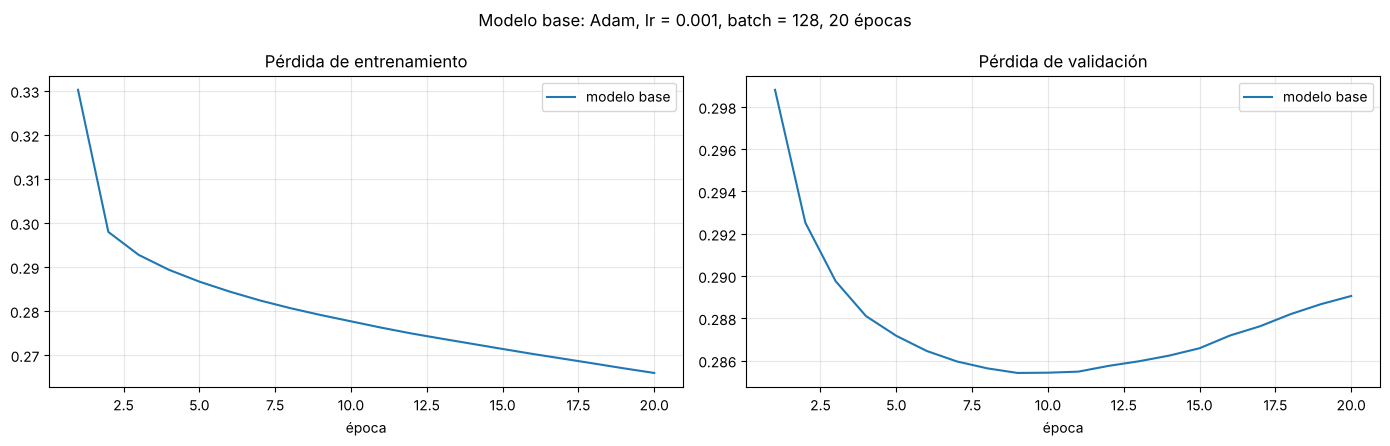

,accuracy,precision,recall,f1,loss_train,loss_val,epocas
modelo base,0.8963,0.6267,0.2834,0.3903,0.2659,0.2891,20


In [13]:
entrenar("base")
graficar_curvas(["base"], ["modelo base"], "Modelo base: Adam, lr = 0.001, batch = 128, 20 épocas")
display(tabla(["base"], ["modelo base"]))

**Interpretación del modelo base**

- **La red aprende:** la pérdida de entrenamiento baja de forma continua y la de validación la acompaña (0,2891 vs. 0,2659 al final), sin una brecha grande.
- **La Accuracy engaña:** 89,6 % de Accuracy es apenas mayor al 88,3 % que obtiene un modelo que siempre responde "no". Lo importante es la clase "yes".
- **Precision aceptable, Recall bajo:** cuando el modelo dice "yes" acierta el 62,7 % de las veces, pero solo detecta al 28,3 % de los clientes que sí contratan. El F1-Score de la clase "yes" es **0,39**.

Los experimentos que siguen buscan mejorar ese equilibrio entre Precision y Recall.

### 2.3 Evidencia del impacto del preprocesamiento

Para respaldar con evidencia dos de las decisiones de la sección 1, se entrena **el mismo modelo base** cambiando solo una cosa a la vez:

- **Con `duration`:** si fuera una variable legítima, las métricas mejorarían moderadamente; si "delata" el resultado, el salto será grande.
- **Sin escalar** las variables numéricas: muestra qué ocurre con la optimización cuando `balance` (miles de euros) convive con `previous` (0 a 5).

,accuracy,precision,recall,f1,loss_train,loss_val,epocas
"Modelo base (sin duration, escalado)",0.8963,0.6267,0.2834,0.3903,0.2659,0.2891,20
Con duration,0.9080,0.6354,0.5025,0.5612,0.1736,0.2082,20
Sin escalar,0.8872,0.5320,0.3035,0.3865,0.6718,0.3378,20


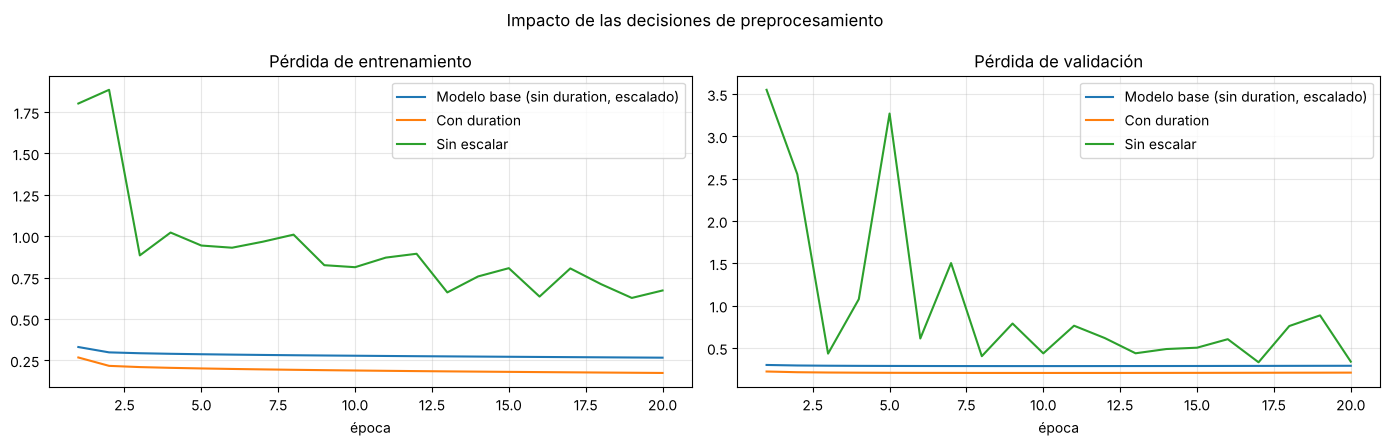

In [14]:
def preparar_variante(incluir_duration=False, escalar=True):
    tabla_v = df.copy()
    tabla_v["contactado_antes"] = (tabla_v["pdays"] != -1).astype(int)
    tabla_v.loc[tabla_v["pdays"] == -1, "pdays"] = 0
    for col in ["default", "housing", "loan"]:
        tabla_v[col] = (tabla_v[col] == "yes").astype(int)
    columnas_num = numericas + (["duration"] if incluir_duration else [])
    if not incluir_duration:
        tabla_v = tabla_v.drop(columns=["duration"])
    tabla_v = pd.get_dummies(tabla_v.drop(columns=["y"]), columns=categoricas, dtype=int)
    tr, va = tabla_v.loc[X_tr.index].copy(), tabla_v.loc[X_va.index].copy()
    if escalar:
        esc = StandardScaler().fit(tr[columnas_num])
        tr[columnas_num] = esc.transform(tr[columnas_num])
        va[columnas_num] = esc.transform(va[columnas_num])
    return tr.values.astype("float32"), va.values.astype("float32")


entrenar("prep_con_duration", datos=preparar_variante(incluir_duration=True))
entrenar("prep_sin_escalar", datos=preparar_variante(escalar=False))
nombres_prep = ["base", "prep_con_duration", "prep_sin_escalar"]
etiquetas_prep = ["Modelo base (sin duration, escalado)", "Con duration", "Sin escalar"]
display(tabla(nombres_prep, etiquetas_prep))
graficar_curvas(nombres_prep, etiquetas_prep, "Impacto de las decisiones de preprocesamiento")

**Qué muestran los dos experimentos (validación, misma red y mismos hiperparámetros)**

- **Con `duration`:** el F1 de la clase "yes" sube de **0,390 a 0,561** y el Recall de 0,28 a 0,50. Parece una gran mejora, pero es ilegítima: la duración de la llamada solo se conoce una vez terminada, así que el modelo "ve" parte del resultado. Por eso `duration` queda fuera y todas las métricas del informe son las de un modelo realista.
- **Sin escalar:** el F1 es parecido (0,387), pero la pérdida de entrenamiento queda mucho más alta (0,672 vs. 0,266) y la de validación también (0,338 vs. 0,289), y la Precision cae de 0,63 a 0,53. Variables como `balance` (hasta 102.127) dominan sobre otras de rango 0–5, y la red aprende peor y de forma menos estable. Escalar mejora la calidad del aprendizaje aunque el F1 no cambie mucho.

## 3. Experimentos controlados: tasa de aprendizaje, batch y épocas

En cada experimento se cambia **un solo parámetro** y se deja todo lo demás igual. Después se fija el mejor valor en `CONFIG`, que pasa a ser el punto de partida del siguiente experimento.

### 3.1 Tasa de aprendizaje

Es el tamaño del paso con que se mueven los parámetros contra el gradiente. Si es muy pequeña, la red converge pero demora mucho; si es muy grande, "salta" sobre el mínimo y puede no converger. Se prueban 0,0001 · 0,001 · 0,01.

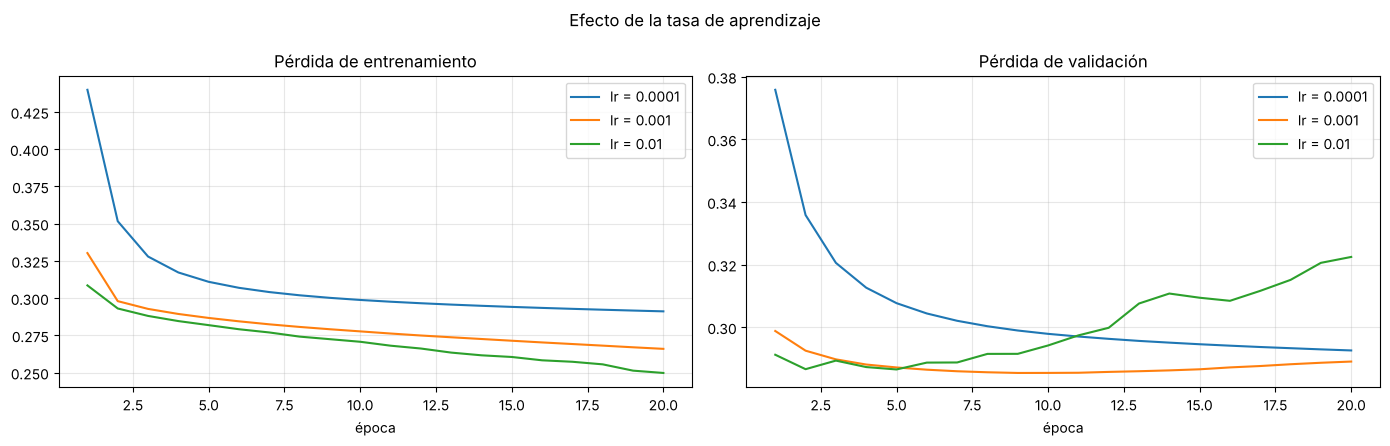

,accuracy,precision,recall,f1,loss_train,loss_val,epocas
lr = 0.0001,0.8950,0.6752,0.1990,0.3074,0.2911,0.2926,20
lr = 0.001,0.8963,0.6267,0.2834,0.3903,0.2659,0.2891,20
lr = 0.01,0.8851,0.5235,0.2103,0.3001,0.2498,0.3225,20


In [15]:
VALORES_LR = [0.0001, 0.001, 0.01]
for v in VALORES_LR:
    entrenar(f"lr_{v}", lr=v)
nombres_lr = [f"lr_{v}" for v in VALORES_LR]
etiquetas_lr = [f"lr = {v}" for v in VALORES_LR]
graficar_curvas(nombres_lr, etiquetas_lr, "Efecto de la tasa de aprendizaje")
display(tabla(nombres_lr, etiquetas_lr))

**Análisis del experimento de tasa de aprendizaje**

- **lr = 0,0001 (muy pequeña):** la pérdida de entrenamiento baja lentamente (0,2911 tras 20 épocas) y la red detecta pocos clientes (Recall 0,20; F1 0,31). Converge, pero con muchos más pasos de los necesarios.
- **lr = 0,001:** el mejor equilibrio, con F1 **0,39** y pérdida de validación 0,2891.
- **lr = 0,01 (muy grande):** la pérdida de entrenamiento es la más baja (0,2498), pero la de **validación es la más alta (0,3225)** y la Precision cae a 0,52. Los pasos son tan grandes que la red memoriza el entrenamiento y generaliza peor.

**Decisión: tasa de aprendizaje = 0,001**, la que entrega el mejor F1 con un entrenamiento estable.

In [16]:
CONFIG["lr"] = float(elegir_mejor(nombres_lr).split("_")[1])
print("Tasa de aprendizaje elegida (mejor F1 en validación):", CONFIG["lr"])

Tasa de aprendizaje elegida (mejor F1 en validación): 0.001


### 3.2 Tamaño de batch

El descenso del gradiente estocástico estima el error con un lote (batch) de datos al azar en lugar de usar todos los datos. Un batch pequeño actualiza los parámetros más veces por época; uno grande actualiza menos veces. Se prueban 64 · 128 · 512 con la tasa de aprendizaje elegida.

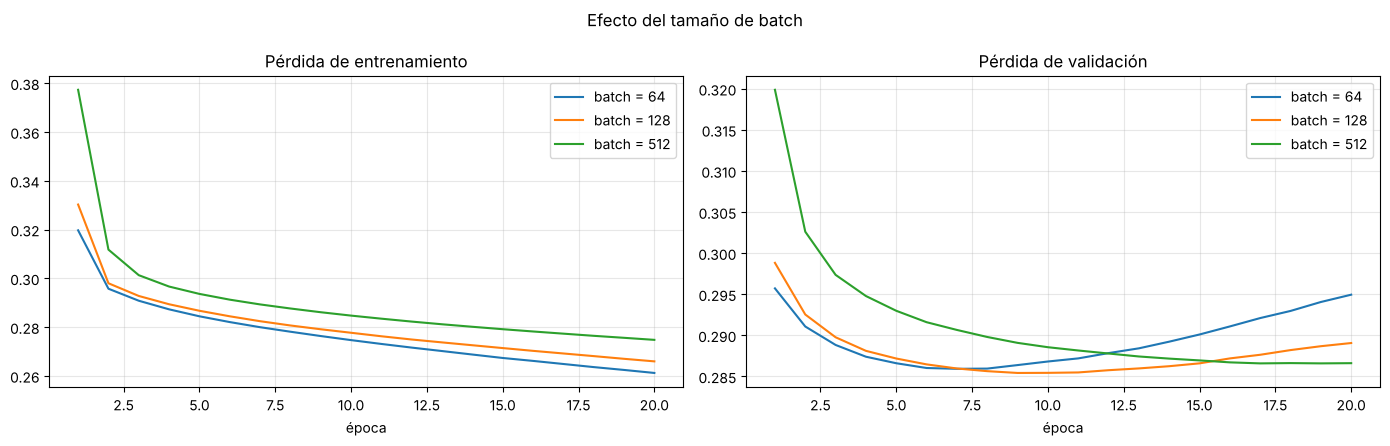

,accuracy,precision,recall,f1,loss_train,loss_val,epocas
batch = 64,0.8946,0.6238,0.2506,0.3576,0.2612,0.2949,20
batch = 128,0.8963,0.6267,0.2834,0.3903,0.2659,0.2891,20
batch = 512,0.8950,0.6434,0.2317,0.3407,0.2748,0.2866,20


In [17]:
VALORES_BATCH = [64, 128, 512]
for v in VALORES_BATCH:
    entrenar(f"batch_{v}", batch=v)
nombres_batch = [f"batch_{v}" for v in VALORES_BATCH]
etiquetas_batch = [f"batch = {v}" for v in VALORES_BATCH]
graficar_curvas(nombres_batch, etiquetas_batch, "Efecto del tamaño de batch")
display(tabla(nombres_batch, etiquetas_batch))

**Análisis del experimento de tamaño de batch**

Por época, la red actualiza sus parámetros 495 veces con batch 64, 248 con batch 128 y 62 con batch 512.

- **Batch 64:** más actualizaciones, menor pérdida de entrenamiento (0,2612) pero mayor pérdida de validación (0,2949): empieza a sobreajustar antes. F1 0,36.
- **Batch 128:** mejor F1 (**0,39**) y buen equilibrio entre ambas pérdidas.
- **Batch 512:** pocas actualizaciones, por lo que aprende más lento (pérdida de entrenamiento más alta, 0,2748) y detecta menos clientes (Recall 0,23; F1 0,34). Su menor pérdida de validación (0,2866) refleja que aún no sobreajusta, no que sea mejor.

**Decisión: batch = 128**, que entrega el mejor F1 con un costo de tiempo razonable.

In [18]:
CONFIG["batch"] = int(elegir_mejor(nombres_batch).split("_")[1])
print("Batch elegido (mejor F1 en validación):", CONFIG["batch"])

Batch elegido (mejor F1 en validación): 128


### 3.3 Número de épocas

Una época es una pasada completa por los datos de entrenamiento. Con pocas épocas la red queda **subajustada** (todavía hay progreso por hacer) y con demasiadas se **sobreajusta** (aprende patrones del entrenamiento que no sirven con datos nuevos: la pérdida de validación deja de bajar y empieza a subir). Se prueban 5 · 20 · 40 épocas.

,accuracy,precision,recall,f1,loss_train,loss_val,epocas
5 épocas,0.8943,0.6390,0.2229,0.3305,0.2867,0.2872,5
20 épocas,0.8963,0.6267,0.2834,0.3903,0.2659,0.2891,20
40 épocas,0.8921,0.5724,0.3086,0.4010,0.2492,0.3025,40


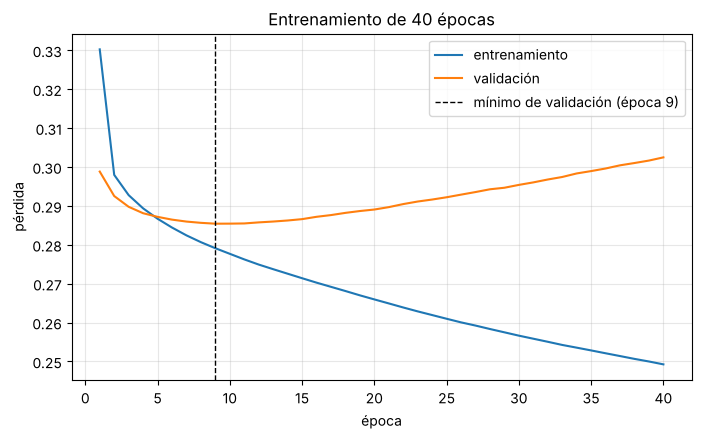

In [19]:
VALORES_EPOCAS = [5, 20, 40]
for v in VALORES_EPOCAS:
    entrenar(f"epocas_{v}", epocas=v)
nombres_ep = [f"epocas_{v}" for v in VALORES_EPOCAS]
etiquetas_ep = [f"{v} épocas" for v in VALORES_EPOCAS]
display(tabla(nombres_ep, etiquetas_ep))

h = RESULTADOS["epocas_40"]["historia"]
mejor_epoca = int(np.argmin(h["val_loss"])) + 1
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, 41), h["loss"], label="entrenamiento")
plt.plot(range(1, 41), h["val_loss"], label="validación")
plt.axvline(mejor_epoca, color="black", linestyle="--", linewidth=1, label=f"mínimo de validación (época {mejor_epoca})")
plt.xlabel("época")
plt.ylabel("pérdida")
plt.title("Entrenamiento de 40 épocas")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Análisis del experimento de épocas**

- **Pocas épocas (5):** la red está subajustada, con el F1 más bajo (0,33).
- **El gráfico muestra el sobreajuste:** la pérdida de entrenamiento baja siempre, pero la de validación toca su **mínimo en la época 9** y desde ahí sube (0,3025 en la época 40). A partir de ahí la red empieza a memorizar el entrenamiento.
- **El F1 sigue subiendo hasta 40 épocas (0,40)**, pero a costa de un intercambio: el Recall sube (0,22 → 0,31) mientras la **Precision baja** (0,64 → 0,57), porque la red marca como "yes" a más clientes.

**Decisión: 40 épocas**, que es lo que mejor F1 entrega, aplicando el mismo criterio que en el resto del informe. Se deja anotado que desde la época 9 ya hay sobreajuste: es el problema que se aborda con las técnicas de regularización de la sección 6.

In [20]:
CONFIG["epocas"] = int(elegir_mejor(nombres_ep).split("_")[1])
print("Épocas elegidas (mejor F1 en validación):", CONFIG["epocas"])
print("Época con menor pérdida de validación en el entrenamiento de 40 épocas:", mejor_epoca)

Épocas elegidas (mejor F1 en validación): 40
Época con menor pérdida de validación en el entrenamiento de 40 épocas: 9


## 4. Funciones de activación y de error

### 4.1 Funciones de activación

Se comparan las tres funciones vistas en clase, cada una con su inicialización (He para ReLU y Xavier para sigmoide y tanh):

- **Sigmoide:** da valores entre 0 y 1 y se **satura** en los extremos, donde su pendiente es casi cero y la red "no aprende".
- **Tanh:** da valores entre −1 y 1; funciona mejor que la sigmoide pero también se satura en los extremos.
- **ReLU:** vale 0 para los negativos y es la identidad para los positivos; su gradiente no desaparece.

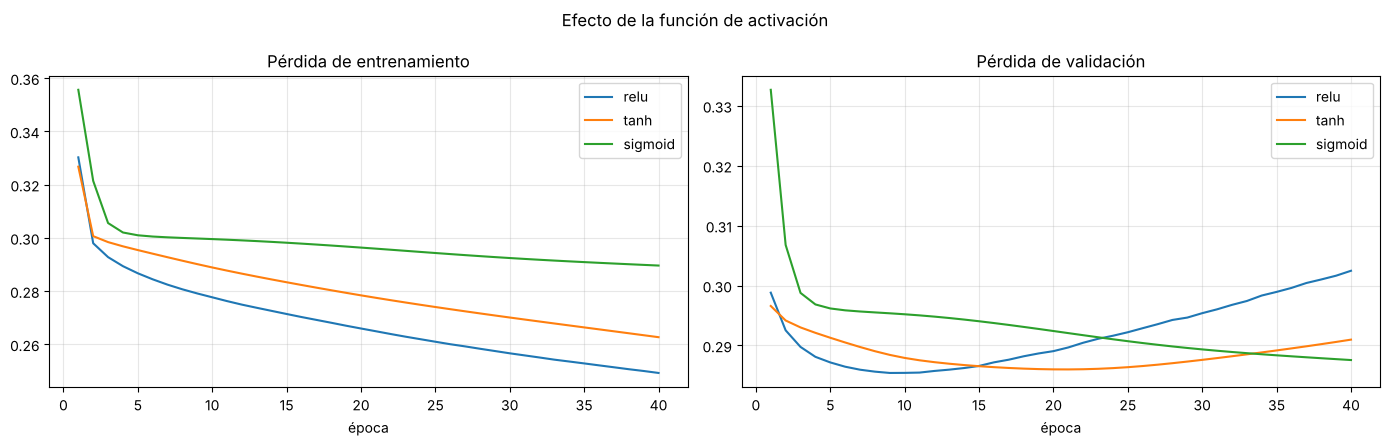

,accuracy,precision,recall,f1,loss_train,loss_val,epocas
relu,0.8921,0.5724,0.3086,0.4010,0.2492,0.3025,40
tanh,0.8934,0.6086,0.2506,0.3550,0.2627,0.2910,40
sigmoid,0.8952,0.6520,0.2242,0.3336,0.2896,0.2876,40


In [21]:
ACTIVACIONES = ["relu", "tanh", "sigmoid"]
for a in ACTIVACIONES:
    entrenar(f"act_{a}", activacion=a)
nombres_act = [f"act_{a}" for a in ACTIVACIONES]
graficar_curvas(nombres_act, ACTIVACIONES, "Efecto de la función de activación")
display(tabla(nombres_act, ACTIVACIONES))

**Análisis de las funciones de activación** (40 épocas)

| Función | F1 | Observación |
|---|---|---|
| **ReLU** | **0,401** | La pérdida de entrenamiento baja más rápido (0,2492) y es la que detecta más clientes (Recall 0,31). |
| **Tanh** | 0,355 | Aprende más lento (pérdida de entrenamiento 0,2627). |
| **Sigmoide** | 0,334 | La más lenta (0,2896): al saturarse, su pendiente es muy baja y la red aprende poco por época. |

Las pérdidas de validación de tanh (0,2910) y sigmoide (0,2876) son menores que la de ReLU (0,3025) solo porque **aprendieron menos** en 40 épocas, no porque generalicen mejor. El orden ReLU > tanh > sigmoide coincide con lo visto en clase.

**Función de salida:** en todos los casos se usa una neurona con sigmoide, porque entrega un valor entre 0 y 1 que se interpreta como la probabilidad de que el cliente contrate, que es lo que necesita un problema de clasificación binaria.

**Decisión: ReLU** en las capas ocultas.

In [22]:
CONFIG["activacion"] = elegir_mejor(nombres_act).split("_")[1]
print("Activación elegida (mejor F1 en validación):", CONFIG["activacion"])

Activación elegida (mejor F1 en validación): relu


### 4.2 Funciones de error

Se compara la **entropía cruzada binaria** con el **error cuadrático medio (MSE)**, que es la función de error usada en el ejemplo de backpropagation visto en clase. Ambas se usan con la misma salida sigmoide. Sus valores de pérdida **no son comparables entre sí** (tienen escalas distintas), por lo que la comparación se hace con las métricas de clasificación.

,accuracy,precision,recall,f1
Entropía cruzada binaria,0.8921,0.5724,0.3086,0.4010
Error cuadrático medio,0.8924,0.5808,0.2897,0.3866


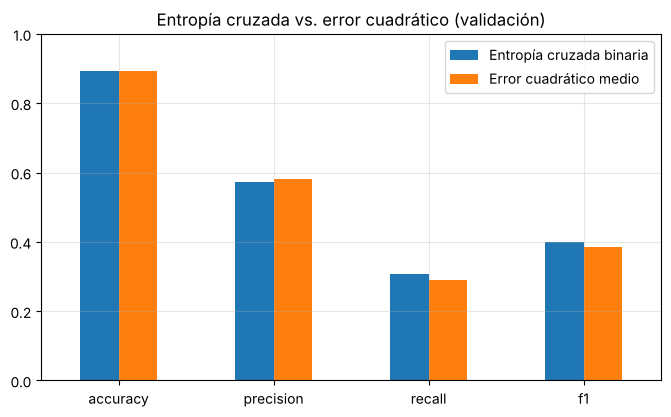

In [23]:
PERDIDAS = {"binary_crossentropy": "Entropía cruzada binaria", "mean_squared_error": "Error cuadrático medio"}
for k in PERDIDAS:
    entrenar(f"perdida_{k}", perdida=k)
nombres_perd = [f"perdida_{k}" for k in PERDIDAS]
display(tabla(nombres_perd, list(PERDIDAS.values()))[["accuracy", "precision", "recall", "f1"]])

etiquetas_perd = list(PERDIDAS.values())
metricas_plot = pd.DataFrame([RESULTADOS[n]["metricas"] for n in nombres_perd], index=etiquetas_perd)[["accuracy", "precision", "recall", "f1"]]
metricas_plot.T.plot(kind="bar", figsize=(8, 4.5), rot=0)
plt.title("Entropía cruzada vs. error cuadrático (validación)")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.show()

**Análisis de las funciones de error**

| Función de error | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Entropía cruzada binaria | 0,8921 | 0,5724 | 0,3086 | **0,4010** |
| Error cuadrático medio | 0,8924 | 0,5808 | 0,2897 | 0,3866 |

La diferencia es pequeña. La entropía cruzada detecta más clientes (mejor Recall y F1) y el error cuadrático acierta un poco más cuando dice "yes" (mejor Precision). Una razón para que la entropía cruzada corrija más rápido viene de backpropagation: en la regla de la cadena, con el error cuadrático el gradiente se multiplica por la derivada de la sigmoide, que es pequeña cuando la sigmoide está saturada; con la entropía cruzada ese factor se cancela.

**Validación con el caso de estudio:** una sigmoide en la salida más la entropía cruzada es la combinación natural cuando la red debe entregar una probabilidad para dos clases.

**Decisión: entropía cruzada binaria.**

In [24]:
CONFIG["perdida"] = elegir_mejor(nombres_perd).replace("perdida_", "")
print("Función de error elegida (mejor F1 en validación):", CONFIG["perdida"])

Función de error elegida (mejor F1 en validación): binary_crossentropy


## 5. Número de capas

Más capas y neuronas permiten aprender patrones más complejos, pero también facilitan el sobreajuste. Se comparan tres tamaños de red con el resto de la configuración ya elegida.

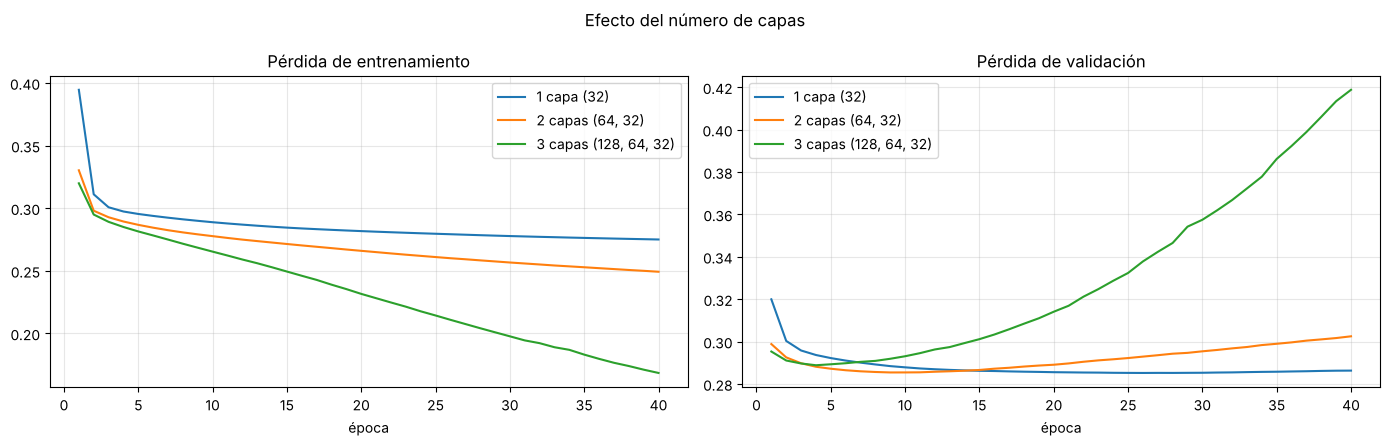

,accuracy,precision,recall,f1,loss_train,loss_val,epocas
1 capa (32),0.8974,0.6775,0.2355,0.3495,0.2750,0.2863,40
"2 capas (64, 32)",0.8921,0.5724,0.3086,0.4010,0.2492,0.3025,40
"3 capas (128, 64, 32)",0.8747,0.4459,0.2909,0.3521,0.1684,0.4188,40


In [25]:
ARQUITECTURAS = {"1 capa (32)": (32,), "2 capas (64, 32)": (64, 32), "3 capas (128, 64, 32)": (128, 64, 32)}
for k, v in ARQUITECTURAS.items():
    entrenar(f"arq_{k}", neuronas=v)
nombres_arq = [f"arq_{k}" for k in ARQUITECTURAS]
graficar_curvas(nombres_arq, list(ARQUITECTURAS), "Efecto del número de capas")
display(tabla(nombres_arq, list(ARQUITECTURAS)))

**Análisis del número de capas**

| Arquitectura | F1 | Pérdida entrenamiento | Pérdida validación |
|---|---|---|---|
| 1 capa (32) | 0,350 | 0,2750 | 0,2863 |
| **2 capas (64, 32)** | **0,401** | 0,2492 | 0,3025 |
| 3 capas (128, 64, 32) | 0,352 | 0,1684 | 0,4188 |

- **Poca capacidad (1 capa):** la red es demasiado simple, detecta menos clientes (Recall 0,24).
- **Mucha capacidad (3 capas):** la pérdida de entrenamiento baja a 0,1684 pero la de validación **sube a 0,4188**. La red memoriza el entrenamiento: sobreajuste claro, con la Precision cayendo a 0,45.
- **2 capas:** el mejor equilibrio.

**Decisión: 2 capas (64, 32)**, la misma arquitectura del modelo base.

In [26]:
CONFIG["neuronas"] = ARQUITECTURAS[elegir_mejor(nombres_arq).replace("arq_", "")]
print("Arquitectura elegida (mejor F1 en validación):", CONFIG["neuronas"])

Arquitectura elegida (mejor F1 en validación): (64, 32)


## 6. Regularización y optimización

El sobreajuste aparece cuando la pérdida de entrenamiento sigue bajando pero la de validación se estanca o sube. Las técnicas de regularización impiden que el modelo se ajuste perfectamente a los datos de entrenamiento para que generalice mejor. Se prueban las vistas en clase contra el mismo modelo **sin regularización**, con el número de épocas ya elegido, para que el sobreajuste sea visible:

- **Dropout (0,3):** apaga al azar el 30 % de las neuronas en cada batch, solo durante el entrenamiento.
- **Regularización L2 (0,001):** penaliza los pesos grandes agregando un término a la función de error.
- **Batch Normalization:** normaliza las salidas de cada capa entre la neurona y la función de activación, estabilizando el entrenamiento.
- **Early Stopping:** detiene el entrenamiento cuando la pérdida de validación deja de mejorar durante 5 épocas y recupera los mejores pesos.
- **Data augmentation:** se descarta porque se usa para generar más imágenes (rotar, recortar, etc.) y no aplica a datos tabulares de clientes.

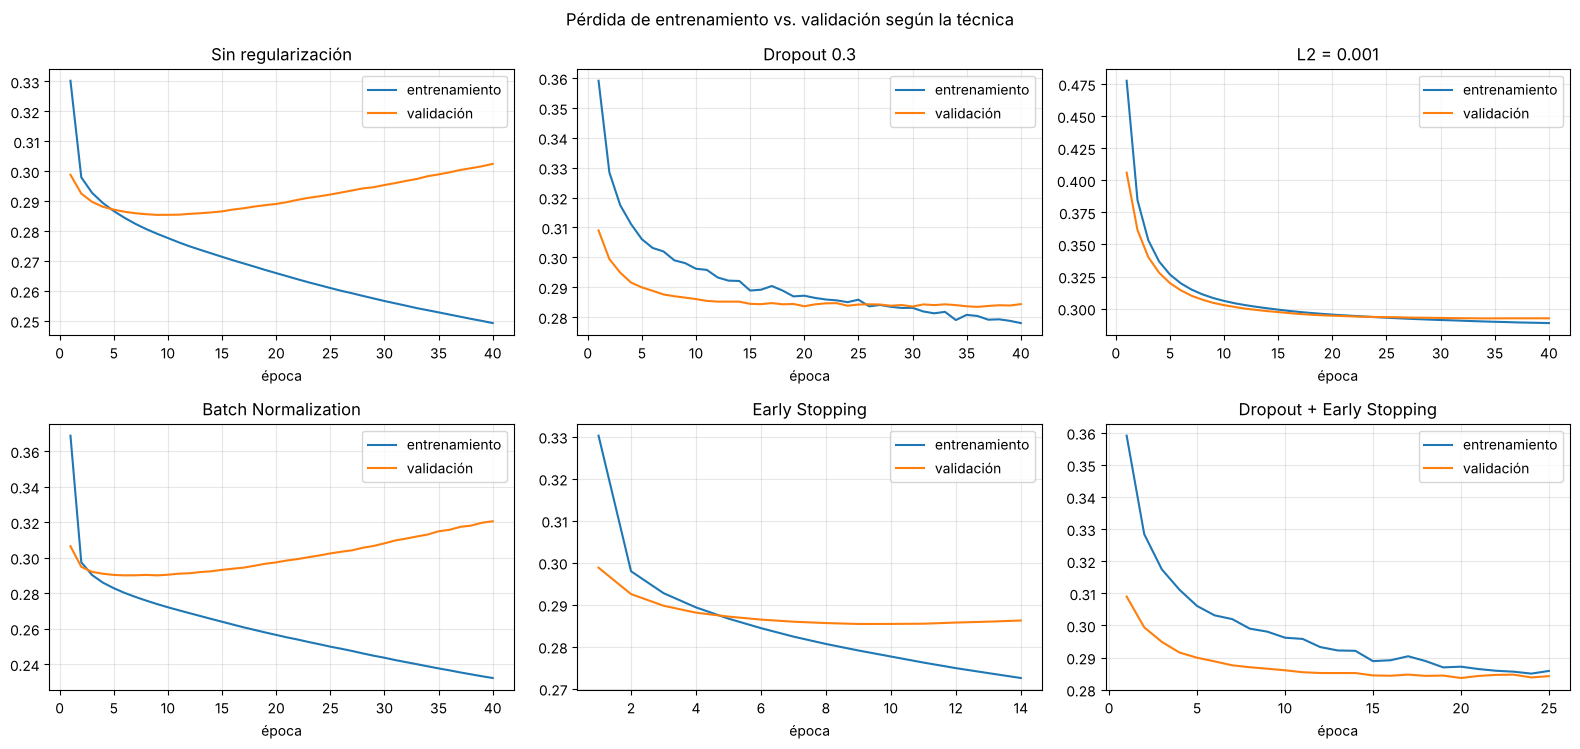

,accuracy,precision,recall,f1,loss_train,loss_val,epocas
Sin regularización,0.8921,0.5724,0.3086,0.4010,0.2492,0.3025,40
Dropout 0.3,0.8963,0.6872,0.2103,0.3221,0.2780,0.2843,40
L2 = 0.001,0.8956,0.6287,0.2645,0.3723,0.2887,0.2924,40
Batch Normalization,0.8866,0.5367,0.2305,0.3225,0.2322,0.3205,40
Early Stopping,0.8949,0.6311,0.2456,0.3536,0.2726,0.2854,14
Dropout + Early Stopping,0.8949,0.6849,0.1889,0.2962,0.2858,0.2836,25


In [27]:
entrenar("reg_ninguna")
entrenar("reg_dropout", dropout=0.3)
entrenar("reg_l2", l2=0.001)
entrenar("reg_batchnorm", batchnorm=True)
entrenar("reg_earlystopping", early_stopping=True)
entrenar("reg_dropout_es", dropout=0.3, early_stopping=True)

nombres_reg = ["reg_ninguna", "reg_dropout", "reg_l2", "reg_batchnorm", "reg_earlystopping", "reg_dropout_es"]
etiquetas_reg = ["Sin regularización", "Dropout 0.3", "L2 = 0.001", "Batch Normalization", "Early Stopping", "Dropout + Early Stopping"]
graficar_train_val(nombres_reg, etiquetas_reg, "Pérdida de entrenamiento vs. validación según la técnica", columnas=3)
display(tabla(nombres_reg, etiquetas_reg))

**Análisis de las técnicas de regularización** (misma red de la sección 5, 40 épocas)

| Técnica | Precision | Recall | F1 | Pérdida validación |
|---|---|---|---|---|
| Sin regularización | 0,572 | 0,309 | **0,401** | 0,3025 |
| Dropout 0,3 | 0,687 | 0,210 | 0,322 | 0,2843 |
| L2 = 0,001 | 0,629 | 0,265 | 0,372 | 0,2924 |
| Batch Normalization | 0,537 | 0,231 | 0,323 | 0,3205 |
| Early Stopping | 0,631 | 0,246 | 0,354 | 0,2854 |
| Dropout + Early Stopping | 0,685 | 0,189 | 0,296 | 0,2836 |

- **Sin regularización:** la pérdida de validación se separa de la de entrenamiento (brecha de 0,053): sobreajuste.
- **Dropout, L2 y Early Stopping** hacen que las curvas de entrenamiento y validación queden **juntas y estables** (con Dropout la brecha baja a 0,006) y reducen la pérdida de validación. Es el efecto esperado: la regularización reduce la diferencia entre el error de entrenamiento y el de generalización. Early Stopping detuvo el entrenamiento en la época 14 (el mínimo fue en la 9) y recuperó los mejores pesos. En L2, la pérdida de entrenamiento incluye el término de penalización.
- **Batch Normalization** no ayudó en este caso: la pérdida de validación siguió subiendo (0,3205) y el F1 bajó.
- **Costo en F1:** al reducir el sobreajuste, la red se vuelve menos "segura", marca menos clientes como "yes", y la **Precision sube pero el Recall baja**; por eso el F1 baja respecto de la red sin regularizar. Es el mismo intercambio visto en el experimento de épocas, en sentido contrario.

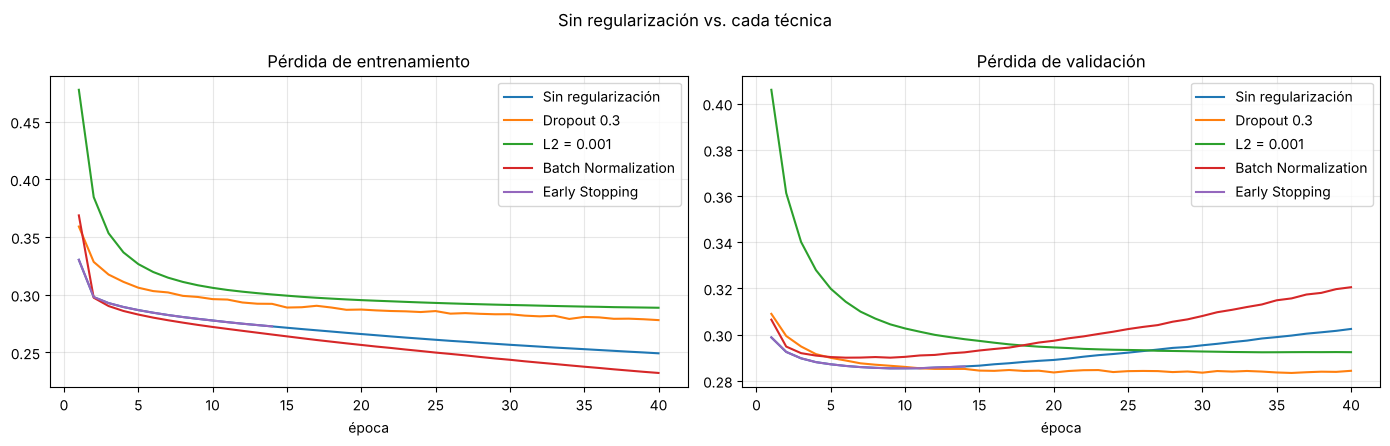

In [28]:
graficar_curvas(["reg_ninguna", "reg_dropout", "reg_l2", "reg_batchnorm", "reg_earlystopping"],
                ["Sin regularización", "Dropout 0.3", "L2 = 0.001", "Batch Normalization", "Early Stopping"],
                "Sin regularización vs. cada técnica")

El gráfico muestra la pérdida de validación de cada técnica: sin regularización sube a medida que avanzan las épocas (sobreajuste), mientras que con Dropout, L2 y Early Stopping se mantiene baja y casi plana, es decir, el entrenamiento es **más estable**.

## 7. Evaluación final

### 7.1 Selección del modelo final

Se mantiene el criterio de todo el informe: entre los modelos regularizados se elige el de **mayor F1-Score de la clase "yes" en validación**, y se verifica que su pérdida de validación sea menor que la del modelo sin regularización. El conjunto de prueba todavía no se ha usado.

In [29]:
candidatos = [n for n in nombres_reg if n != "reg_ninguna"]
FINAL = elegir_mejor(candidatos)
print("Modelo final seleccionado:", FINAL)
print("Configuración:", {k: v for k, v in RESULTADOS[FINAL]["config"].items()})
modelo_final = RESULTADOS[FINAL]["modelo"]
modelo_base = RESULTADOS["base"]["modelo"]

Modelo final seleccionado: reg_l2
Configuración: {'neuronas': (64, 32), 'activacion': 'relu', 'lr': 0.001, 'perdida': 'binary_crossentropy', 'batch': 128, 'epocas': 40, 'dropout': 0.0, 'l2': 0.001, 'batchnorm': False, 'early_stopping': False}


El modelo final es la red de 2 capas con **regularización L2 (0,001)**, que fue la técnica con mayor F1 de validación (0,372) y que además reduce la pérdida de validación respecto del modelo sin regularizar (0,2924 vs. 0,3025). Entre las técnicas probadas es la que menos F1 sacrifica a cambio de estabilidad.

### 7.2 Resultados en el conjunto de prueba

Se mide el **modelo base** y el **modelo final** con los datos de prueba, que no se usaron para entrenar ni para elegir hiperparámetros. También se incluye el modelo trivial que siempre responde "no" como punto de comparación.

,accuracy,precision,recall,f1
Modelo trivial (siempre 'no'),0.8831,0.0000,0.0000,0.0000
Modelo base,0.8941,0.6027,0.2774,0.3800
Modelo final,0.8949,0.6183,0.2636,0.3696


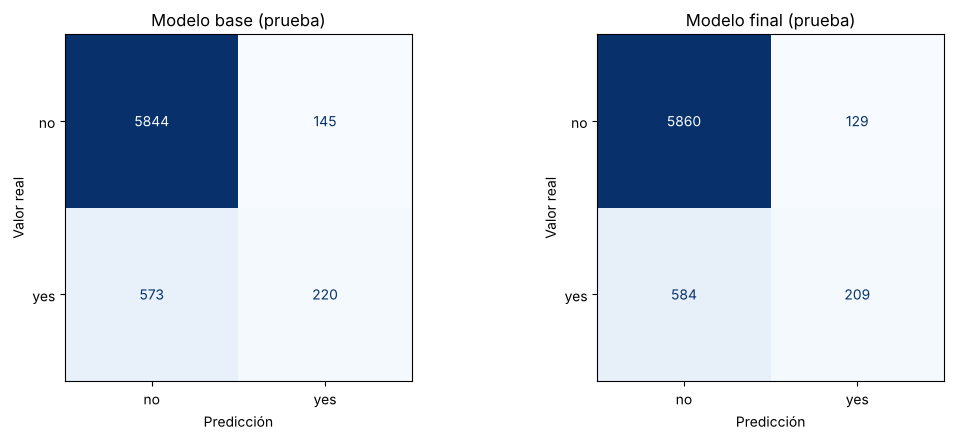

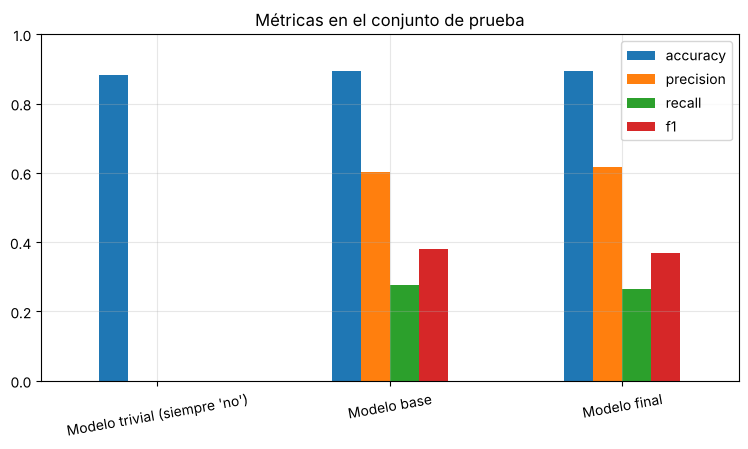

In [30]:
def evaluar(modelo):
    pred = (modelo.predict(X_test, verbose=0).ravel() >= 0.5).astype(int)
    return pred, {"accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred, zero_division=0),
                  "recall": recall_score(y_test, pred, zero_division=0), "f1": f1_score(y_test, pred, zero_division=0)}


pred_base, m_base = evaluar(modelo_base)
pred_final, m_final = evaluar(modelo_final)
pred_trivial = np.zeros_like(y_test)
m_trivial = {"accuracy": accuracy_score(y_test, pred_trivial), "precision": precision_score(y_test, pred_trivial, zero_division=0),
             "recall": recall_score(y_test, pred_trivial, zero_division=0), "f1": f1_score(y_test, pred_trivial, zero_division=0)}
resumen_test = pd.DataFrame([m_trivial, m_base, m_final], index=["Modelo trivial (siempre 'no')", "Modelo base", "Modelo final"])
display(resumen_test.round(4))

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, pred, titulo in zip(axs, [pred_base, pred_final], ["Modelo base", "Modelo final"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["no", "yes"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{titulo} (prueba)")
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")
    ax.grid(False)
plt.tight_layout()
plt.show()

resumen_test.plot(kind="bar", figsize=(9, 4.5), rot=10)
plt.title("Métricas en el conjunto de prueba")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.show()

**Interpretación de los resultados en prueba**

- Ambos modelos superan al modelo trivial en Accuracy y, sobre todo, detectan clientes que contratan (el modelo trivial tiene Precision y Recall 0).
- **Modelo final:** Accuracy 0,895, Precision 0,618, Recall 0,264 y F1 0,370. Frente al modelo base tiene un poco más de Precision (0,618 vs. 0,603) y un poco menos de Recall (0,264 vs. 0,277), con un F1 ligeramente menor (0,370 vs. 0,380). La diferencia es pequeña y es el mismo intercambio de la sección 6: el modelo regularizado es más estable, pero no mejora el F1.
- **Lectura para el banco:** de los clientes que el modelo final marca como "yes", el 61,8 % contrata, más de **5 veces** la tasa general (11,7 %). Pero solo encuentra al 26 % de los que contratarían: el resto no es detectado.

### 7.3 Cálculo de las métricas a partir de la matriz de confusión

Tomando "yes" como la clase positiva, la matriz de confusión tiene cuatro números:

- **VP (verdaderos positivos):** clientes que contrataron y el modelo detectó.
- **FP (falsos positivos):** clientes que no contrataron pero el modelo dijo que sí.
- **FN (falsos negativos):** clientes que sí contrataron y el modelo no detectó.
- **VN (verdaderos negativos):** clientes que no contrataron y el modelo dijo que no.

| Métrica | Fórmula | Qué responde en este problema |
|---|---|---|
| Accuracy | (VP + VN) / total | ¿Qué porcentaje de clientes clasificó bien? |
| Precision | VP / (VP + FP) | De los clientes a los que se llamaría, ¿cuántos realmente contratan? |
| Recall | VP / (VP + FN) | De los clientes que contratarían, ¿cuántos logra encontrar? |
| F1-Score | 2 · Precision · Recall / (Precision + Recall) | Equilibrio entre Precision y Recall. |

In [31]:
vn, fp, fn, vp = confusion_matrix(y_test, pred_final).ravel()
total = vn + fp + fn + vp
acc_m = (vp + vn) / total
prec_m = vp / (vp + fp)
rec_m = vp / (vp + fn)
f1_m = 2 * prec_m * rec_m / (prec_m + rec_m)

print(f"VP = {vp} | FP = {fp} | FN = {fn} | VN = {vn} | total = {total}")
print(f"Accuracy  = ({vp} + {vn}) / {total} = {acc_m:.4f}")
print(f"Precision = {vp} / ({vp} + {fp}) = {prec_m:.4f}")
print(f"Recall    = {vp} / ({vp} + {fn}) = {rec_m:.4f}")
print(f"F1-Score  = 2 · {prec_m:.4f} · {rec_m:.4f} / ({prec_m:.4f} + {rec_m:.4f}) = {f1_m:.4f}")

VP = 209 | FP = 129 | FN = 584 | VN = 5860 | total = 6782
Accuracy  = (209 + 5860) / 6782 = 0.8949
Precision = 209 / (209 + 129) = 0.6183
Recall    = 209 / (209 + 584) = 0.2636
F1-Score  = 2 · 0.6183 · 0.2636 / (0.6183 + 0.2636) = 0.3696


**Ejemplo con el modelo final:** de los 6.782 clientes de prueba, el modelo marcó como "yes" a 338 (209 + 129). De esos, 209 contrataron (**VP**) y 129 no (**FP**). Además, 584 clientes que sí contrataron no fueron detectados (**FN**), y 5.860 clientes que no contratan fueron bien descartados (**VN**).

- **Precision = 209 / 338 = 0,618:** de cada 100 clientes a los que se llamaría, 62 contratan.
- **Recall = 209 / 793 = 0,264:** de cada 100 clientes que contratarían, el modelo encuentra 26.
- **F1-Score = 0,370:** como Recall es mucho menor que Precision, el F1 queda cerca del valor más bajo.

### 7.4 Interpretación de Precision y Recall

Precision y Recall suelen moverse en direcciones opuestas: si el modelo marca como "yes" a más clientes, detecta más de los que contratan (sube el Recall) pero también se equivoca más (baja la Precision). El gráfico muestra cómo cambian ambas métricas, en validación, al cambiar la duración del entrenamiento y la regularización.

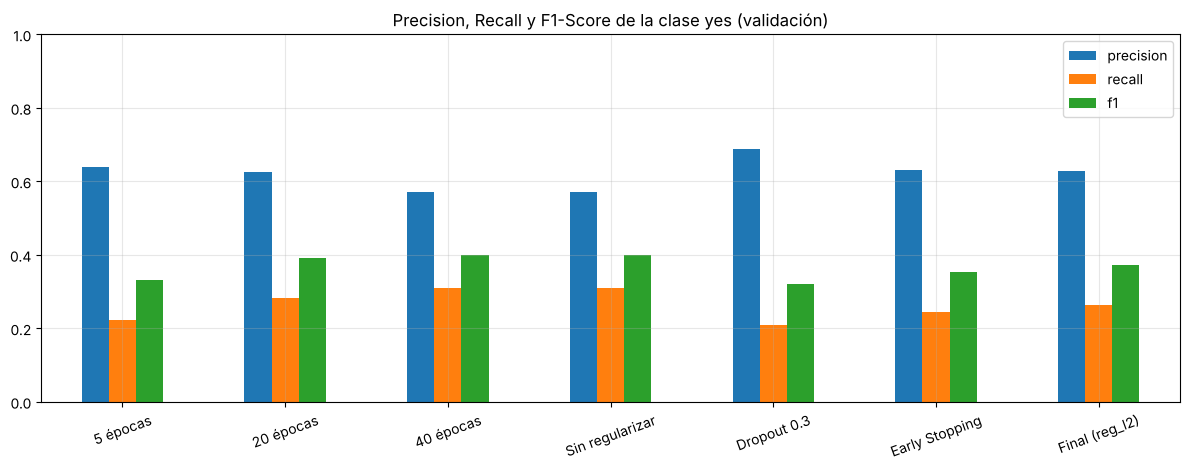

,precision,recall,f1
5 épocas,0.6390,0.2229,0.3305
20 épocas,0.6267,0.2834,0.3903
40 épocas,0.5724,0.3086,0.4010
Sin regularizar,0.5724,0.3086,0.4010
Dropout 0.3,0.6872,0.2103,0.3221
Early Stopping,0.6311,0.2456,0.3536
Final (reg_l2),0.6287,0.2645,0.3723


In [32]:
claves = ["epocas_5", "epocas_20", "epocas_40", "reg_ninguna", "reg_dropout", "reg_earlystopping", FINAL]
etiquetas_pr = ["5 épocas", "20 épocas", "40 épocas", "Sin regularizar", "Dropout 0.3", "Early Stopping", f"Final ({FINAL})"]
pr = pd.DataFrame([RESULTADOS[n]["metricas"] for n in claves], index=etiquetas_pr)[["precision", "recall", "f1"]]
pr.plot(kind="bar", figsize=(12, 4.8), rot=20)
plt.title("Precision, Recall y F1-Score de la clase yes (validación)")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()
display(pr.round(4))

**Cómo mejorar Precision y Recall**

El gráfico muestra que ambas métricas se mueven en sentidos opuestos:

- **Más épocas** (5 → 40) suben el Recall (0,22 → 0,31) y bajan la Precision (0,64 → 0,57).
- **Dropout** lleva la Precision a su máximo (0,69) pero deja el Recall en 0,21.
- **L2** (modelo final) queda en un punto intermedio.

Ninguna técnica mejora ambas a la vez: hay que elegir según lo que más importe al banco. Si llamar a cada cliente tiene un costo alto, conviene una Precision alta (Dropout); si interesa no dejar pasar clientes, un Recall alto (más épocas, sin regularizar).

## 8. Resumen de todas las configuraciones probadas

Todas las pruebas de validación, ordenadas por F1-Score de la clase "yes".

In [33]:
filas = []
for n, v in RESULTADOS.items():
    cfg = v["config"]
    fila = dict(v["metricas"])
    fila.update({"capas": cfg["neuronas"], "activación": cfg["activacion"], "lr": cfg["lr"],
                 "batch": cfg["batch"], "épocas_config": cfg["epocas"], "error": cfg["perdida"], "dropout": cfg["dropout"],
                 "l2": cfg["l2"], "batchnorm": cfg["batchnorm"], "early_stopping": cfg["early_stopping"]})
    filas.append(pd.Series(fila, name=n))
global_df = pd.DataFrame(filas)
columnas_g = ["accuracy", "precision", "recall", "f1", "capas", "activación", "lr", "batch", "épocas_config", "error", "dropout", "l2", "batchnorm", "early_stopping"]
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 250):
    display(global_df[columnas_g].sort_values("f1", ascending=False).round(4))
print("Modelos entrenados:", len(global_df))

,accuracy,precision,recall,f1,capas,activación,lr,batch,épocas_config,error,dropout,l2,batchnorm,early_stopping
prep_con_duration,0.9080,0.6354,0.5025,0.5612,"(64, 32)",relu,0.0010,128,20,binary_crossentropy,0.0,0.000,False,False
epocas_40,0.8921,0.5724,0.3086,0.4010,"(64, 32)",relu,0.0010,128,40,binary_crossentropy,0.0,0.000,False,False
"arq_2 capas (64, 32)",0.8921,0.5724,0.3086,0.4010,"(64, 32)",relu,0.0010,128,40,binary_crossentropy,0.0,0.000,False,False
perdida_binary_crossentropy,0.8921,0.5724,0.3086,0.4010,"(64, 32)",relu,0.0010,128,40,binary_crossentropy,0.0,0.000,False,False
act_relu,0.8921,0.5724,0.3086,0.4010,"(64, 32)",relu,0.0010,128,40,binary_crossentropy,0.0,0.000,False,False
reg_ninguna,0.8921,0.5724,0.3086,0.4010,"(64, 32)",relu,0.0010,128,40,binary_crossentropy,0.0,0.000,False,False
lr_0.001,0.8963,0.6267,0.2834,0.3903,"(64, 32)",relu,0.0010,128,20,binary_crossentropy,0.0,0.000,False,False
batch_128,0.8963,0.6267,0.2834,0.3903,"(64, 32)",relu,0.0010,128,20,binary_crossentropy,0.0,0.000,False,False
epocas_20,0.8963,0.6267,0.2834,0.3903,"(64, 32)",relu,0.0010,128,20,binary_crossentropy,0.0,0.000,False,False
base,0.8963,0.6267,0.2834,0.3903,"(64, 32)",relu,0.0010,128,20,binary_crossentropy,0.0,0.000,False,False


Modelos entrenados: 26


La tabla muestra todas las pruebas. El mayor F1 de validación (0,401) lo tiene la red de 2 capas con ReLU y entropía cruzada entrenada 40 épocas sin regularizar, pero es también la que más sobreajusta. Varias filas repiten los mismos valores porque la configuración base se incluyó como un punto de comparación dentro de cada experimento.

## 9. Análisis de resultados y conclusiones

### Hallazgos clave

1. **Preprocesamiento:** se excluyó `duration` porque solo se conoce después de llamar al cliente; se codificaron las variables de texto con one-hot y se estandarizaron las numéricas usando solo los datos de entrenamiento.
2. **Parámetros de entrenamiento:** la mejor tasa de aprendizaje fue 0,001 (0,01 sobreajusta y 0,0001 aprende muy lento) y el mejor batch fue 128. La pérdida de validación se hace mínima en la época 9 y luego sube: hay sobreajuste desde ahí, aunque el F1 siga mejorando hasta la época 40 a costa de la Precision.
3. **Impacto de las funciones:** con ReLU el F1 fue 0,401, con tanh 0,355 y con sigmoide 0,334: elegir sigmoide en las capas ocultas habría bajado el F1 un 17 %. En el error, la entropía cruzada (0,401) superó levemente al error cuadrático (0,387).
4. **Arquitectura:** 2 capas fue lo mejor; con 3 capas la pérdida de validación se disparó (0,4188), señal de sobreajuste.
5. **Regularización:** Dropout, L2 y Early Stopping reducen el sobreajuste y estabilizan el entrenamiento, pero bajan el Recall. Batch Normalization no ayudó en este problema.
6. **Resultado final (prueba):** Accuracy 0,895, Precision 0,618, Recall 0,264 y F1 0,370. El modelo acierta 6 de cada 10 veces que dice "yes" (más de 5 veces mejor que llamar al azar), pero detecta solo a 1 de cada 4 clientes que contratarían.

### Limitaciones y posibles mejoras

- **El desbalance de clases** (12 % "yes") explica el Recall bajo: equivocarse hacia el "no" sale barato para la red. Una mejora sería conseguir más ejemplos de clientes que contratan, que según lo visto en clase es lo que más ayuda al aprendizaje.
- **Ajustar el umbral de decisión:** la red entrega una probabilidad y se clasificó "yes" desde 0,5. Bajar ese corte aumentaría el Recall a costa de Precision, según lo que más le convenga al banco.
- **Los resultados dependen de una sola semilla y de una sola partición.** Las diferencias de F1 de ±0,02 entre configuraciones son pequeñas; una validación cruzada daría resultados más confiables.
- **Más ajuste de hiperparámetros** (por ejemplo, otros valores de Dropout o L2, o combinarlos) podría mejorar el equilibrio entre Precision y Recall.